# TP API
---

##### Realizar una petición GET al sitio web de la UNO y mostrar el código de respuesta.

In [ ]:
import requests
import pandas as pd

response = requests.get("https://www.uno.edu.ar")

print("Respuesta", response.status_code)#mostrar el cofigo de respta.


Respuesta 200


##### Realizar una petición GET a https://httpbin.org/get y mostrar:
* código de estado
* URL de la respuesta
* contenido en texto

In [ ]:
import requests
import pandas as pd

response = requests.get("https://httpbin.org/get")


print("Respuesta", response.status_code)
print("URL", response.url)
print("Texto",  response.text)

Respuesta 200
URL https://httpbin.org/get
Texto {
  "args": {}, 
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate, zstd", 
    "Host": "httpbin.org", 
    "User-Agent": "python-requests/2.34.2", 
    "X-Amzn-Trace-Id": "Root=1-6ac6cbef-184def7b4a7341fa1f54c60f"
  }, 
  "origin": "186.22.16.132", 
  "url": "https://httpbin.org/get"
}



##### Enviar parámetros en la consulta (?nombre=Juan&edad=30) y verificar que el servidor los reciba.

In [ ]:
response = requests.get("https://httpbin.org/get?nombre=Juan&edad=30")
print(response.text)
print("Respuesta", response.status_code)



#Agrega datos directamente usando la url

print("Contenido:", response.json()["args"])  
#Muestra lo parametros recibidos


{
  "args": {
    "edad": "30", 
    "nombre": "Juan"
  }, 
  "headers": {
    "Accept": "*/*", 
    "Accept-Encoding": "gzip, deflate, zstd", 
    "Host": "httpbin.org", 
    "User-Agent": "python-requests/2.34.2", 
    "X-Amzn-Trace-Id": "Root=1-6ac80179-3fa4754113871e82441f757f"
  }, 
  "origin": "186.22.16.132", 
  "url": "https://httpbin.org/get?nombre=Juan&edad=30"
}

Respuesta 200
Contenido: {'edad': '30', 'nombre': 'Juan'}


##### Enviar un formulario (json) con POST a https://httpbin.org/post y muestra la respuesta.

In [28]:
import requests
import pandas as pd

# Enviar datos con POST
response = requests.post("https://httpbin.org/post", json={"nombre": "Juan", "edad": 30})

# Mostrar lo que pide la consigna
print("Código de respuesta:", response.status_code)
print("URL:", response.url)

# Convertir la respuesta en JSON y pasarlo a DataFrame
data = response.json()
df = pd.DataFrame([data["json"]])   # tomo solo la parte del formulario recibido
df.head()



Código de respuesta: 200
URL: https://httpbin.org/post


,edad,nombre
0,30,Juan


##### Enviar una cabecera personalizada (User-Agent) y comprueba que el servidor la reciba.

In [29]:
import requests

headers={
    "User-Argent" : "MiAplicacionQA/1.0"
}

#envío lapeticion
response =requests.get("https://httpbin.org/get", headers=headers)

#muestro el codigo de respuesta
print("codigo de respuesta", response.status_code)


# Mostrar solo la parte de headers que recibio el servidor
print("Cabeceras recibidas por el servidor:", response.json()["headers"]["User-Agent"])


codigo de respuesta 200
Cabeceras recibidas por el servidor: python-requests/2.34.2


##### Descargar una imagen (https://httpbin.org/image/png) y guardarla en su disco.

In [ ]:
import requests

# URL de la imagen
url = "https://httpbin.org/image/png"

# Hacer la petición GET
response = requests.get(url)

# Guarda la imagen en disco
with open("imagen.png", "wb") as f:
    f.write(response.content)

print("Código de respuesta:", response.status_code)
print("Imagen guardada como imagen.png")


Código de respuesta: 200
Imagen guardada como imagen.png


##### Enviar una cookie (https://httpbin.org/cookies) y verificar que el servidor la reciba.

In [31]:
import requests

# Definir cookies
cookies = {
    "usuario": "Pamela",
    "rol": "estudiante"
}

# Enviar la petición con cookies
response = requests.get("https://httpbin.org/cookies", cookies=cookies)

# Mostrar código de respuesta
print("Código de respuesta:", response.status_code)

# Mostrar las cookies que recibió el servidor
print("Cookies recibidas por el servidor:", response.json()["cookies"])


Código de respuesta: 200
Cookies recibidas por el servidor: {'rol': 'estudiante', 'usuario': 'Pamela'}


##### Hacer una petición a https://httpbin.org/redirect/3 y analizar:
* historial (history)
* URL final (url)

In [32]:
import requests

# Hacer la petición que redirige 3 veces
response = requests.get("https://httpbin.org/redirect/3")

# Mostrar código de respuesta final
print("Código de respuesta:", response.status_code)

# Mostrar historial de redirecciones
print("Historial de redirecciones:")
for r in response.history:
    print(r.status_code, r.url)

# Mostrar la URL final
print("URL final:", response.url)


Código de respuesta: 200
Historial de redirecciones:
302 https://httpbin.org/redirect/3
302 https://httpbin.org/relative-redirect/2
302 https://httpbin.org/relative-redirect/1
URL final: https://httpbin.org/get


##### Hacer una petición a una URL inexistente y usar raise_for_status() para capturar el error.

In [33]:
import requests

try:
    response = requests.get("https://httpbin.org/status/404")
    response.raise_for_status()   # lanza excepción si no es 200
except requests.exceptions.HTTPError as e:
    print("Error capturado:", e)


Error capturado: 404 Client Error: NOT FOUND for url: https://httpbin.org/status/404


##### Descargar un archivo grande (https://httpbin.org/stream/5) y procesa su contenido línea por línea con iter_lines().

In [ ]:
import requests

response = requests.get("https://httpbin.org/stream/5", stream=True)

print("Código de respuesta:", response.status_code)

for linea in response.iter_lines():
    if linea:   # evitar líneas vacías
        print(linea.decode("utf-8"))


##### Crear una función que consulte una API pública (por ejemplo, https://jsonplaceholder.typicode.com/posts) y:
* Obtenga todos los posts
* Muestre los títulos
* Permita enviar un nuevo post con POST

In [34]:
import requests

def manejar_posts():
    # Obtener todos los posts
    response = requests.get("https://jsonplaceholder.typicode.com/posts")
    posts = response.json()

    # Mostrar títulos
    print("Títulos de los primeros 5 posts:")
    for p in posts[:5]:
        print("-", p["title"])

    # Enviar un nuevo post con POST
    nuevo = {"title": "Mi post de prueba", "body": "Contenido de ejemplo", "userId": 1}
    r_post = requests.post("https://jsonplaceholder.typicode.com/posts", json=nuevo)
    print("Respuesta al POST:", r_post.status_code)
    print("Post creado:", r_post.json())

manejar_posts()


Títulos de los primeros 5 posts:
- sunt aut facere repellat provident occaecati excepturi optio reprehenderit
- qui est esse
- ea molestias quasi exercitationem repellat qui ipsa sit aut
- eum et est occaecati
- nesciunt quas odio
Respuesta al POST: 201
Post creado: {'title': 'Mi post de prueba', 'body': 'Contenido de ejemplo', 'userId': 1, 'id': 101}


##### Buscar información específica usando parámetros GET (ej: buscar en GitHub: https://api.github.com/)

In [38]:
import requests

# Buscar repositorios con parámetro GET
response = requests.get("https://api.github.com/search/repositories", 
                        params={"q": "python", "sort": "stars"})

print("Código de respuesta:", response.status_code)

# Mostrar los nombres de los primeros 5 repositorios
data = response.json()
for repo in data["items"][:5]:
    print("-", repo["full_name"])


Código de respuesta: 200
- donnemartin/system-design-primer
- vinta/awesome-python
- practical-tutorials/project-based-learning
- TheAlgorithms/Python
- tensorflow/tensorflow


In [39]:
import requests
import pandas as pd

response = requests.get("https://www.uno.edu.ar")

print("Respuesta", response.status_code)#mostrar el codigo de resta.


Respuesta 200


##### Crear una función que utilizando la API swapi (https://swapi.dev/) muestre la lista de personajes, cada vez que muestre la información de una página preguntará si quiere seguir mostrando más personajes. A continuación pedirá el nombre de un personaje y te dará información sobre él.

In [40]:
import requests

def mostrar_personajes():
    url = "https://swapi.dev/api/people/"
    while url:
        response = requests.get(url)
        data = response.json()
        
        # Mostrar personajes de la página actual
        for personaje in data["results"]:
            print("-", personaje["name"])
        
        # Preguntar si seguir
        seguir = input("¿Quieres ver más personajes? (s/n): ")
        if seguir.lower() != "s":
            break
        
        url = data["next"]  # siguiente página

    # Buscar información de un personaje
    nombre = input("Ingresa el nombre de un personaje: ")
    for personaje in data["results"]:
        if personaje["name"].lower() == nombre.lower():
            print("Información:", personaje)
            break

mostrar_personajes()


- Luke Skywalker
- C-3PO
- R2-D2
- Darth Vader
- Leia Organa
- Owen Lars
- Beru Whitesun lars
- R5-D4
- Biggs Darklighter
- Obi-Wan Kenobi


##### Trabajar con una API pública que le permita obtener datos, con esos datos responder alguna pregunta de interés para procesarlos (usar pandas) y luego hacer una visualización (usar matplotlib).

Código de respuesta: 200
Cantidad de posts por usuario:
userId
1     10
2     10
3     10
4     10
5     10
6     10
7     10
8     10
9     10
10    10
Name: count, dtype: int64


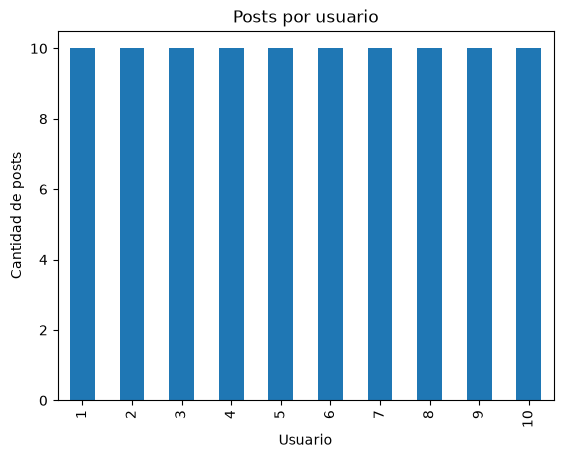

In [44]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# 1. Consultar la API pública
response = requests.get("https://jsonplaceholder.typicode.com/posts")
print("Código de respuesta:", response.status_code)

# 2. Convertir la respuesta a JSON y luego a DataFrame
posts = response.json()
df = pd.DataFrame(posts)

# 3. Procesar los datos: contar cuántos posts tiene cada usuario
conteo = df["userId"].value_counts().sort_index()

print("Cantidad de posts por usuario:")
print(conteo)

# 4. Visualizar con matplotlib
conteo.plot(kind="bar", title="Posts por usuario")
plt.xlabel("Usuario")
plt.ylabel("Cantidad de posts")
plt.show()





In [ ]:
import requests
import pandas as pd

response = requests.get("https://jsonplaceholder.typicode.com/users")
df = pd.DataFrame(response.json() )
df.head() #muestra las primera 5 filas

#GET  es una peticion q se usa para pedir datos.

,id,name,username,email,address,phone,website,company
0,1,Leanne Graham,Bret,Sincere@april.biz,"{'street': 'Kulas Light', 'suite': 'Apt. 556',...",1-770-736-8031 x56442,hildegard.org,"{'name': 'Romaguera-Crona', 'catchPhrase': 'Mu..."
1,2,Ervin Howell,Antonette,Shanna@melissa.tv,"{'street': 'Victor Plains', 'suite': 'Suite 87...",010-692-6593 x09125,anastasia.net,"{'name': 'Deckow-Crist', 'catchPhrase': 'Proac..."
2,3,Clementine Bauch,Samantha,Nathan@yesenia.net,"{'street': 'Douglas Extension', 'suite': 'Suit...",1-463-123-4447,ramiro.info,"{'name': 'Romaguera-Jacobson', 'catchPhrase': ..."
3,4,Patricia Lebsack,Karianne,Julianne.OConner@kory.org,"{'street': 'Hoeger Mall', 'suite': 'Apt. 692',...",493-170-9623 x156,kale.biz,"{'name': 'Robel-Corkery', 'catchPhrase': 'Mult..."
4,5,Chelsey Dietrich,Kamren,Lucio_Hettinger@annie.ca,"{'street': 'Skiles Walks', 'suite': 'Suite 351...",(254)954-1289,demarco.info,"{'name': 'Keebler LLC', 'catchPhrase': 'User-c..."
